# Classical Classification of Roud Song Clusters

Uses three classifiers:
K-nearest neighbors (KNN), a support vector machine (SVM) and linear discriminant analysis (LDA).

In [1]:
import numpy as np
import pandas as pd

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, adjusted_rand_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

SEED = 1337  # for determinism

In [2]:
# Load the data, drop duplicates and any songs without lyrics
raw = pd.read_csv("dataset-v2.csv", dtype=str)

df_lyrics2 = pd.DataFrame({
    "name":    raw["title"],
    "roud":    raw["roud"],   # the answer we're evaluating
    "variant": raw["title"] + "# " + raw["version"],
    "lyrics":  raw["lyrics"],
})

df_lyrics2 = df_lyrics2.dropna(subset=["lyrics", "roud"])
df_lyrics2 = df_lyrics2.drop_duplicates(subset=["name", "lyrics", "roud"]).reset_index(drop=True)

print(len(df_lyrics2), "versions of", df_lyrics2.roud.nunique(), "songs")
df_lyrics2.head()

6828 versions of 2167 songs


,name,roud,variant,lyrics
0,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 1,"It being on the twenty-third of June-o,\nAs I ..."
1,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 2,As I was sitting with my glass and spoon\nOne ...
2,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 3,"It being on the third of June,\nas I sat weavi..."
3,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 4,As I was sitting with my jug and spoon\nOn one...
4,A Maid in Bedlam / Abroad As I Was Walking,578,A Maid in Bedlam / Abroad As I Was Walking# 1,Abroad as I was walking one evening in the spr...


In [3]:
# Keep ballads of three versions, so every fold below can train and test on each ballad
df_lyrics2["roud_count"] = df_lyrics2.groupby("roud")["roud"].transform("count")
df_roud_multiples = df_lyrics2[df_lyrics2["roud_count"] >= 3].reset_index(drop=True)
print(len(df_roud_multiples), "variants of", df_roud_multiples.roud.nunique(), "ballads kept")

5023 variants of 887 ballads kept


Each song is predicted once by models that never saw it (3-fold cross-validation). The TF-IDF step sits inside each
pipeline, so its vocabulary also comes from the training songs only.

- **KNN** predicts the ballad of the most similar songs, using the same cosine distance as the TF-IDF clustering notebook.
- **SVM** learns a linear boundary between each ballad and the rest.
- **LDA** can't use the huge sparse TF-IDF matrix directly, so TruncatedSVD compresses it to 300 dimensions first.

In [4]:
# shared setup: tf-idf settings, and the same 3 folds for every model
tfidf_params = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                    strip_accents="unicode", dtype=np.float32)

lyrics = df_roud_multiples["lyrics"].to_numpy()
roud = df_roud_multiples["roud"].to_numpy()
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(lyrics, roud))

df_pred = df_roud_multiples.copy()

In [5]:
# KNN: predict the ballad of the most similar songs
knn = make_pipeline(TfidfVectorizer(**tfidf_params),
                    KNeighborsClassifier(n_neighbors=3, metric="cosine", weights="distance"))
df_pred["pred_knn"] = cross_val_predict(knn, lyrics, roud, cv=folds)
print(f"KNN accuracy: {accuracy_score(roud, df_pred['pred_knn']):.3f}")

KNN accuracy: 0.968


In [6]:
# SVM: learn a linear boundary between each ballad and the rest
svm = make_pipeline(TfidfVectorizer(**tfidf_params), LinearSVC(random_state=SEED))
df_pred["pred_svm"] = cross_val_predict(svm, lyrics, roud, cv=folds)
print(f"SVM accuracy: {accuracy_score(roud, df_pred['pred_svm']):.3f}")

SVM accuracy: 0.974


In [7]:
# LDA: compress tf-idf to 300 dimensions first, since LDA can't use the sparse matrix directly
lda = make_pipeline(TfidfVectorizer(**tfidf_params), TruncatedSVD(n_components=300, random_state=SEED),
                    LinearDiscriminantAnalysis())
df_pred["pred_lda"] = cross_val_predict(lda, lyrics, roud, cv=folds)
print(f"LDA accuracy: {accuracy_score(roud, df_pred['pred_lda']):.3f}")

LDA accuracy: 0.868



- **Accuracy** = share of songs given the correct Roud number. **Macro F1** averages the score over ballads, so rare ballads count as much as common ones.
- **Macro precision** = when a model predicts a ballad, how often it is right, averaged over ballads. Low precision goes with mixed clusters.
- **Macro recall** = how many of a ballad's songs the model finds, averaged over ballads. Low recall goes with split ballads.


In [11]:
# how good are the predictions?
def score_model(name, pred_col):
    pred = df_pred[pred_col].to_numpy()
    per_cluster = df_pred.groupby(pred_col)["roud"].nunique()
    per_ballad  = df_pred.groupby("roud")[pred_col].nunique()
    fold_acc = [accuracy_score(roud[test_idx], pred[test_idx]) for _, test_idx in folds]
    return {
        "model": name,
        "accuracy": accuracy_score(roud, pred),
        "accuracy_fold_std": np.std(fold_acc),
        "macro_f1": f1_score(roud, pred, average="macro", zero_division=0),
        "macro_precision": precision_score(roud, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(roud, pred, average="macro", zero_division=0),
        "ARI": adjusted_rand_score(roud, pred),
        "pure_clusters": (per_cluster == 1).sum(),
        "mixed_clusters": (per_cluster > 1).sum(),
        "split_ballads": (per_ballad > 1).sum(),
    }

df_results = pd.DataFrame([
    score_model("KNN", "pred_knn"),
    score_model("SVM", "pred_svm"),
    score_model("LDA", "pred_lda"),
]).set_index("model").round(3)
df_results

,accuracy,accuracy_fold_std,macro_f1,macro_precision,macro_recall,ARI,pure_clusters,mixed_clusters,split_ballads
model,,,,,,,,,
KNN,0.968,0.002,0.962,0.969,0.962,0.941,766,116,116
SVM,0.974,0.002,0.970,0.978,0.967,0.948,786,98,101
LDA,0.868,0.010,0.889,0.936,0.869,0.598,752,133,440


In [12]:
#t-sne, turning many dimensions into two. This is only for drawing the chart: the models above don't use it

vectorizer = TfidfVectorizer(**tfidf_params)
X = vectorizer.fit_transform(lyrics)

X_dist = np.clip(1.0 - X.dot(X.T).toarray(), 0.0, None)
X_dist = (X_dist + X_dist.T) / 2
np.fill_diagonal(X_dist, 0.0)

X_tsne = TSNE(n_components=2, metric="precomputed", init="random", random_state=SEED, n_jobs=-1).fit_transform(X_dist)
df_pred["tsne"] = X_tsne.tolist()
df_pred[["name", "roud", "tsne"]].head()

,name,roud,tsne
0,A Jug of Punch / The 23 rd of June,1808,"[30.460075, -45.934883]"
1,A Jug of Punch / The 23 rd of June,1808,"[30.530083, -44.938114]"
2,A Jug of Punch / The 23 rd of June,1808,"[30.471596, -45.755547]"
3,A Jug of Punch / The 23 rd of June,1808,"[30.49386, -45.520935]"
4,A Maid in Bedlam / Abroad As I Was Walking,578,"[14.264931, 51.624977]"


In [13]:
# chart/plot: where each model went wrong, and how evenly it did across ballads
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

def plot_model(name, pred_col):
    pred = df_pred[pred_col].to_numpy()
    correct = pred == roud

    fig, (ax_map, ax_f1) = plt.subplots(1, 2, figsize=(14, 6), width_ratios=[3, 2])
    fig.suptitle(f"{name}: {correct.mean():.1%} of songs predicted correctly")

    # wrong songs are drawn last so the correct ones can't hide them
    ax_map.scatter(X_tsne[correct, 0], X_tsne[correct, 1], s=8, linewidths=0, color="#c9c8c2",
                   label=f"Correct ({correct.sum()})")
    ax_map.scatter(X_tsne[~correct, 0], X_tsne[~correct, 1], s=14, linewidths=0, color="#eb6834",
                   label=f"Wrong ({(~correct).sum()})")
    ax_map.set_aspect("equal")
    ax_map.set_xlabel("t-SNE X")
    ax_map.set_ylabel("t-SNE Y")
    ax_map.legend(frameon=False, loc="upper right")

    ballad_f1 = f1_score(roud, pred, labels=np.unique(roud), average=None, zero_division=0)
    ax_f1.hist(ballad_f1, bins=np.linspace(0, 1, 11), color="#2a78d6", edgecolor="white", linewidth=2)
    ax_f1.set_xlabel("F1 score of the ballad")
    ax_f1.set_ylabel("Number of ballads")
    ax_f1.grid(axis="y", color="#e8e7e2")
    ax_f1.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(f"ballad_predictions_{name.lower()}.png", dpi=200)
    plt.show()

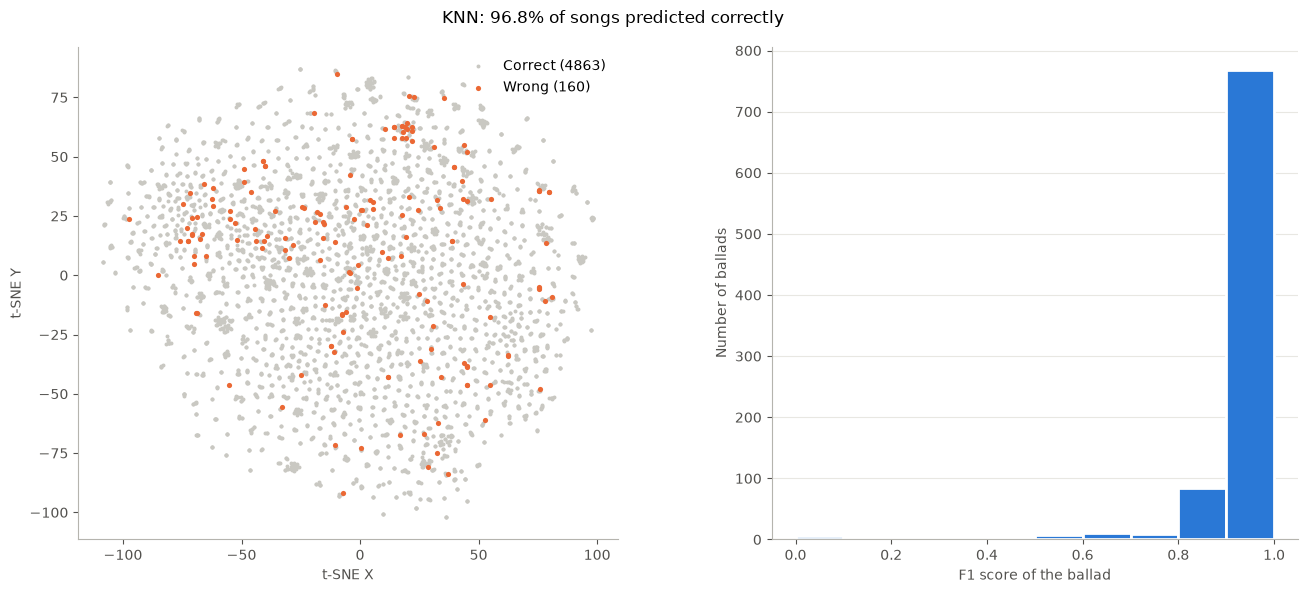

In [14]:
plot_model("KNN", "pred_knn")

In [ ]:
plot_model("SVM", "pred_svm")

In [ ]:
plot_model("LDA", "pred_lda")

In [ ]:
# compare all of the models on one chart
ax = df_results[["accuracy", "macro_precision", "macro_recall", "macro_f1", "ARI"]].plot.bar(
    figsize=(13, 6), width=0.85, edgecolor="white", linewidth=2,
    color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", color="#52514e", fontsize=8)

ax.set_title("Model comparison (higher is better)")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", color="#e8e7e2")
ax.set_axisbelow(True)
ax.legend(["Accuracy", "Macro precision", "Macro recall", "Macro F1", "ARI"], frameon=False, ncols=5,
          loc="upper center", bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig("ballad_predictions_comparison.png", dpi=200)
plt.show()

Each ballad's lyrics were turned into word scores (TF-IDF) over single words and word pairs, as in the clustering notebook.
Instead of looking for groups on their own, KNN, SVM and LDA were shown the Roud numbers of two thirds of the songs and asked to
predict the Roud numbers of the remaining third, repeated until every song had been predicted once. The results table compares each
model with the baseline and with the clustering notebook's metrics. In the charts, orange points are songs the model got wrong, and the histograms show how many ballads reached each F1 score.